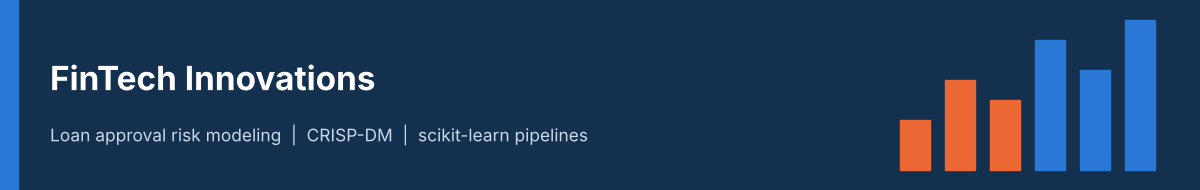

# Automating Loan Approval at FinTech Innovations
### A CRISP-DM study: predicting loan approval decisions with scikit-learn pipelines

## Overview

**Bottom line.** A tuned, fully pipelined **logistic regression** reproduces FinTech Innovations' historical approve/decline decisions with a **test ROC-AUC of 0.995**. At a cost-optimised threshold (0.86) it is right **97.7% of the time when it approves** and finds **81% of approvable applicants**, cutting expected error cost per application by **72%** versus the best trivial policy (0.068 vs 0.239). Used as a three-band triage, the model could decide about **91% of applications automatically** and send the remaining **9%** to analysts. Income, total debt-to-income and interest rate drive the decisions; age and marital status add nothing and can be removed.

**Read this before trusting the numbers.**
1. The label is the *historical decision*, not repayment. The model copies the current policy; it does not measure credit-loss risk.
2. `RiskScore` was excluded because it is computed from the decision (target leakage).
3. The data look synthetic (the supplied generator script says so), so real-world performance will be lower than 0.995.

**The story:** the manual process is slow and inconsistent -> the data show it follows a fairly smooth scoring rule -> a simple, explainable model learns that rule almost perfectly -> the real work is deciding how much to automate and checking fairness, not squeezing out more AUC.


**Notebook map (CRISP-DM)**

1. Business Understanding
2. Data Understanding (EDA and feature understanding)
3. Data Preparation (pipelines)
4. Modeling (baselines, cross-validation, tuning)
5. Evaluation (test performance, segments, bias, feature importance)
6. Conclusion: executive summary, recommendations, next steps

## 1. Business Understanding

### 1.1 The current process and its limits

FinTech Innovations decides loan applications **manually**: an analyst reads each application, weighs credit score, income, debt load and history, and approves or declines. The dataset we were given (20,000 past applications, 35 columns) records those outcomes. A manual process like this has predictable limits:

| Limitation | Why it matters |
|---|---|
| **Slow and capacity-bound** | Throughput grows only by hiring analysts; applicants wait and some walk away. |
| **Inconsistent** | Two analysts can decide the same file differently, and one analyst can drift over time. |
| **Costly** | Analyst time is spent on clear-cut cases that rules could settle. |
| **Hard to audit** | The reasons behind a decision are in someone's head, which is a problem for regulators and for applicants who ask "why?". |
| **Prone to bias** | Subjective judgement can pick up proxies for age, marital status or education. |

### 1.2 Stakeholders and what they need

| Stakeholder | Need |
|---|---|
| **Credit risk / Chief Risk Officer** | Few bad approvals; a transparent, controllable risk appetite (a dial, not a black box). |
| **Underwriters / loan officers** | Automation of the easy cases, a clear score and reasons for the hard ones. |
| **Finance / executives** | Higher volume at lower cost per decision; interest income not lost to wrongful declines. |
| **Compliance and legal** | Explainable, consistent, non-discriminatory decisions with an audit trail. |
| **Applicants** | Fast, fair decisions and a reason when declined. |
| **Data / IT** | A reproducible pipeline that can be monitored and retrained. |

### 1.3 What the two kinds of error cost

We treat **"approved" as the positive class (1)**.

| Error | Meaning | Business consequence |
|---|---|---|
| **False Positive (FP)** | Model approves an applicant the policy would decline | Credit-loss exposure. This is the expensive error. |
| **False Negative (FN)** | Model declines an applicant the policy would approve | Lost interest income, a lost customer, and possible fairness complaints. |

We assume an FP is **5 times as costly as an FN** (`FP_COST = 5`, `FN_COST = 1`). This ratio is an **assumption**: the data holds no loan-loss or margin figures, so Risk and Finance should replace it. The code uses one constant, so changing it re-runs the whole analysis, including the decision threshold.

> **Important caveat.** The label is the *historical approval decision*, not whether the borrower later repaid. A model trained on it learns to **reproduce the existing policy** (including its quirks and biases), not to predict default. That is still useful (consistency and speed) but it is not a credit-loss model. See the recommendations for how to close that gap.

### 1.4 Classification or regression?

The thing we must decide is binary (approve or decline), so we use **classification** on `LoanApproved`.

* A regression on `RiskScore` is the tempting alternative, but `RiskScore` is **not a safe target or feature**: the generating script supplied with the data multiplies it by 0.8 for approved loans, so it is calculated *from the decision*. Predicting it would only re-derive the label (see section 2.5).
* A classifier still gives the benefits of a score: `predict_proba` ranks applicants and lets Risk move the approval **threshold** to match its appetite.

### 1.5 Modeling goals and success criteria

| Metric | Why we chose it |
|---|---|
| **ROC-AUC** | Threshold-free measure of how well the model ranks approvable above declinable applicants. Robust to the 24/76 class imbalance. Primary tuning metric. |
| **Average precision (PR-AUC)** | Focuses on the minority (approved) class. Reported as a cross-check on ROC-AUC. |
| **Precision (approved)** | Of the loans we approve, how many would the policy approve? Low precision means credit exposure. |
| **Recall (approved)** | Of the approvable applicants, how many do we approve? Low recall means lost revenue. |
| **F1** | One number balancing precision and recall. |
| **Custom: expected cost per application** | `(5 x FP + 1 x FN) / N`. Turns the error trade-off from 1.3 into money-like units and is used to pick the decision threshold. |
| *Accuracy (reported, not optimised)* | Misleading here: "decline everyone" scores 76%. |

**Baselines and targets (set before modeling):**

* *Decline-everyone* baseline: accuracy 76%, recall 0, cost per application about 0.24. *Approve-everyone* baseline: cost about 3.8. The best trivial policy is therefore about **0.24**.
* A **logistic regression** on the full feature set is our "simple model" floor.
* **Targets for the final model on held-out data:** ROC-AUC >= 0.90, precision >= 0.80 and recall >= 0.70 at the chosen threshold, and cost per application <= 40% of the best trivial baseline (<= about 0.096).

## 2. Data Understanding

### 2.1 Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import (StandardScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, FunctionTransformer)
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, make_scorer,
                             RocCurveDisplay, ConfusionMatrixDisplay, roc_curve)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Business assumption (see 1.3): a wrongly approved loan costs 5x a wrongly declined one.
FP_COST, FN_COST = 5, 1

# Plot style: two class colours used consistently (approved = blue, declined = orange)
C_APP, C_DEC, C_NEUTRAL = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})
pd.set_option("display.max_columns", 50, "display.width", 140)

In [2]:
# Locate the data file (works locally, in Colab or in the sandbox where this was built)
CANDIDATES = ["financial_loan_data.csv", "data/financial_loan_data.csv",
              "/mnt/user-data/attachments/661bd08f-d41d-5b74-8aa1-acc681dfc2ca/2a4156b2-financial_loan_data.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape :", raw.shape)
raw.head(3)

Loaded: /mnt/user-data/attachments/661bd08f-d41d-5b74-8aa1-acc681dfc2ca/2a4156b2-financial_loan_data.csv
Shape : (20000, 35)


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.354418,1,2,0.358336,No,Home,0,29,9,7632.0,1202,146111,19183,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.087827,5,3,0.330274,No,Debt Consolidation,0,21,9,4627.0,3460,53204,9595,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.137414,2,0,0.244729,No,Education,0,20,22,886.0,895,25176,128874,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0


### 2.2 Basic data characteristics

In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(),
                     "n_missing": raw.isna().sum(), "pct_missing": (raw.isna().mean()*100).round(2)})
display(info)
print("Duplicate rows:", raw.duplicated().sum())

,dtype,n_unique,n_missing,pct_missing
Age,int64,63,0,0.00
AnnualIncome,str,17516,0,0.00
CreditScore,int64,322,0,0.00
EmploymentStatus,str,3,0,0.00
EducationLevel,str,5,901,4.50
Experience,int64,62,0,0.00
LoanAmount,int64,15578,0,0.00
LoanDuration,int64,10,0,0.00
MaritalStatus,str,4,1331,6.65
NumberOfDependents,int64,6,0,0.00


Duplicate rows: 0


Two things stand out immediately: `AnnualIncome` is stored as **text** (`"$39,948.00"`) and must be converted, and three columns have missing values (`EducationLevel`, `MaritalStatus`, `SavingsAccountBalance`). Everything else is complete and there are no duplicate rows.

In [ ]:

df = raw.copy()
df["AnnualIncome"] = df["AnnualIncome"].str.replace(r"[$,]", "", regex=True).astype(float)
df["BankruptcyHistory"] = df["BankruptcyHistory"].map({"No": 0, "Yes": 1}).astype(int)


df.drop(columns=[TARGET]).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,20000.0,39.75,11.62,18.00,32.00,40.00,48.00,80.00
AnnualIncome,20000.0,59161.47,40350.85,15000.00,31679.00,48566.00,74391.00,485341.00
CreditScore,20000.0,571.61,51.00,343.00,540.00,578.00,609.00,712.00
Experience,20000.0,17.52,11.32,0.00,9.00,17.00,25.00,61.00
LoanAmount,20000.0,24882.87,13427.42,3674.00,15575.00,21914.50,30835.00,184732.00
LoanDuration,20000.0,54.06,24.66,12.00,36.00,48.00,72.00,120.00
NumberOfDependents,20000.0,1.52,1.39,0.00,0.00,1.00,2.00,5.00
MonthlyDebtPayments,20000.0,454.29,240.51,50.00,286.00,402.00,564.00,2919.00
CreditCardUtilizationRate,20000.0,0.29,0.16,0.00,0.16,0.27,0.39,0.92
NumberOfOpenCreditLines,20000.0,3.02,1.74,0.00,2.00,3.00,4.00,13.00


### 2.3 Distributions

**Target.** Roughly one application in four is approved, so the classes are imbalanced (about 24% / 76%). We will therefore stratify every split and avoid plain accuracy.

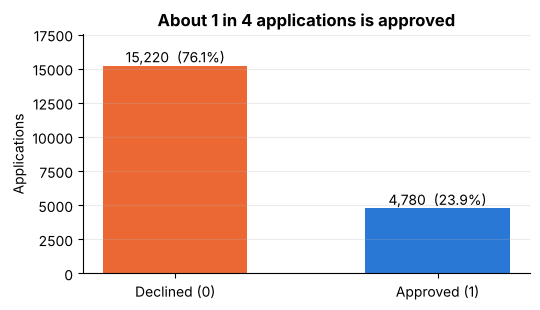

In [5]:
vc = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["Declined (0)", "Approved (1)"], vc.values, color=[C_DEC, C_APP], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, v+250, f"{v:,}  ({v/len(df):.1%})", ha="center", fontsize=10)
ax.set_ylim(0, vc.max()*1.15); ax.set_ylabel("Applications"); ax.grid(axis="x", visible=False)
ax.set_title("About 1 in 4 applications is approved")
plt.tight_layout(); plt.show()

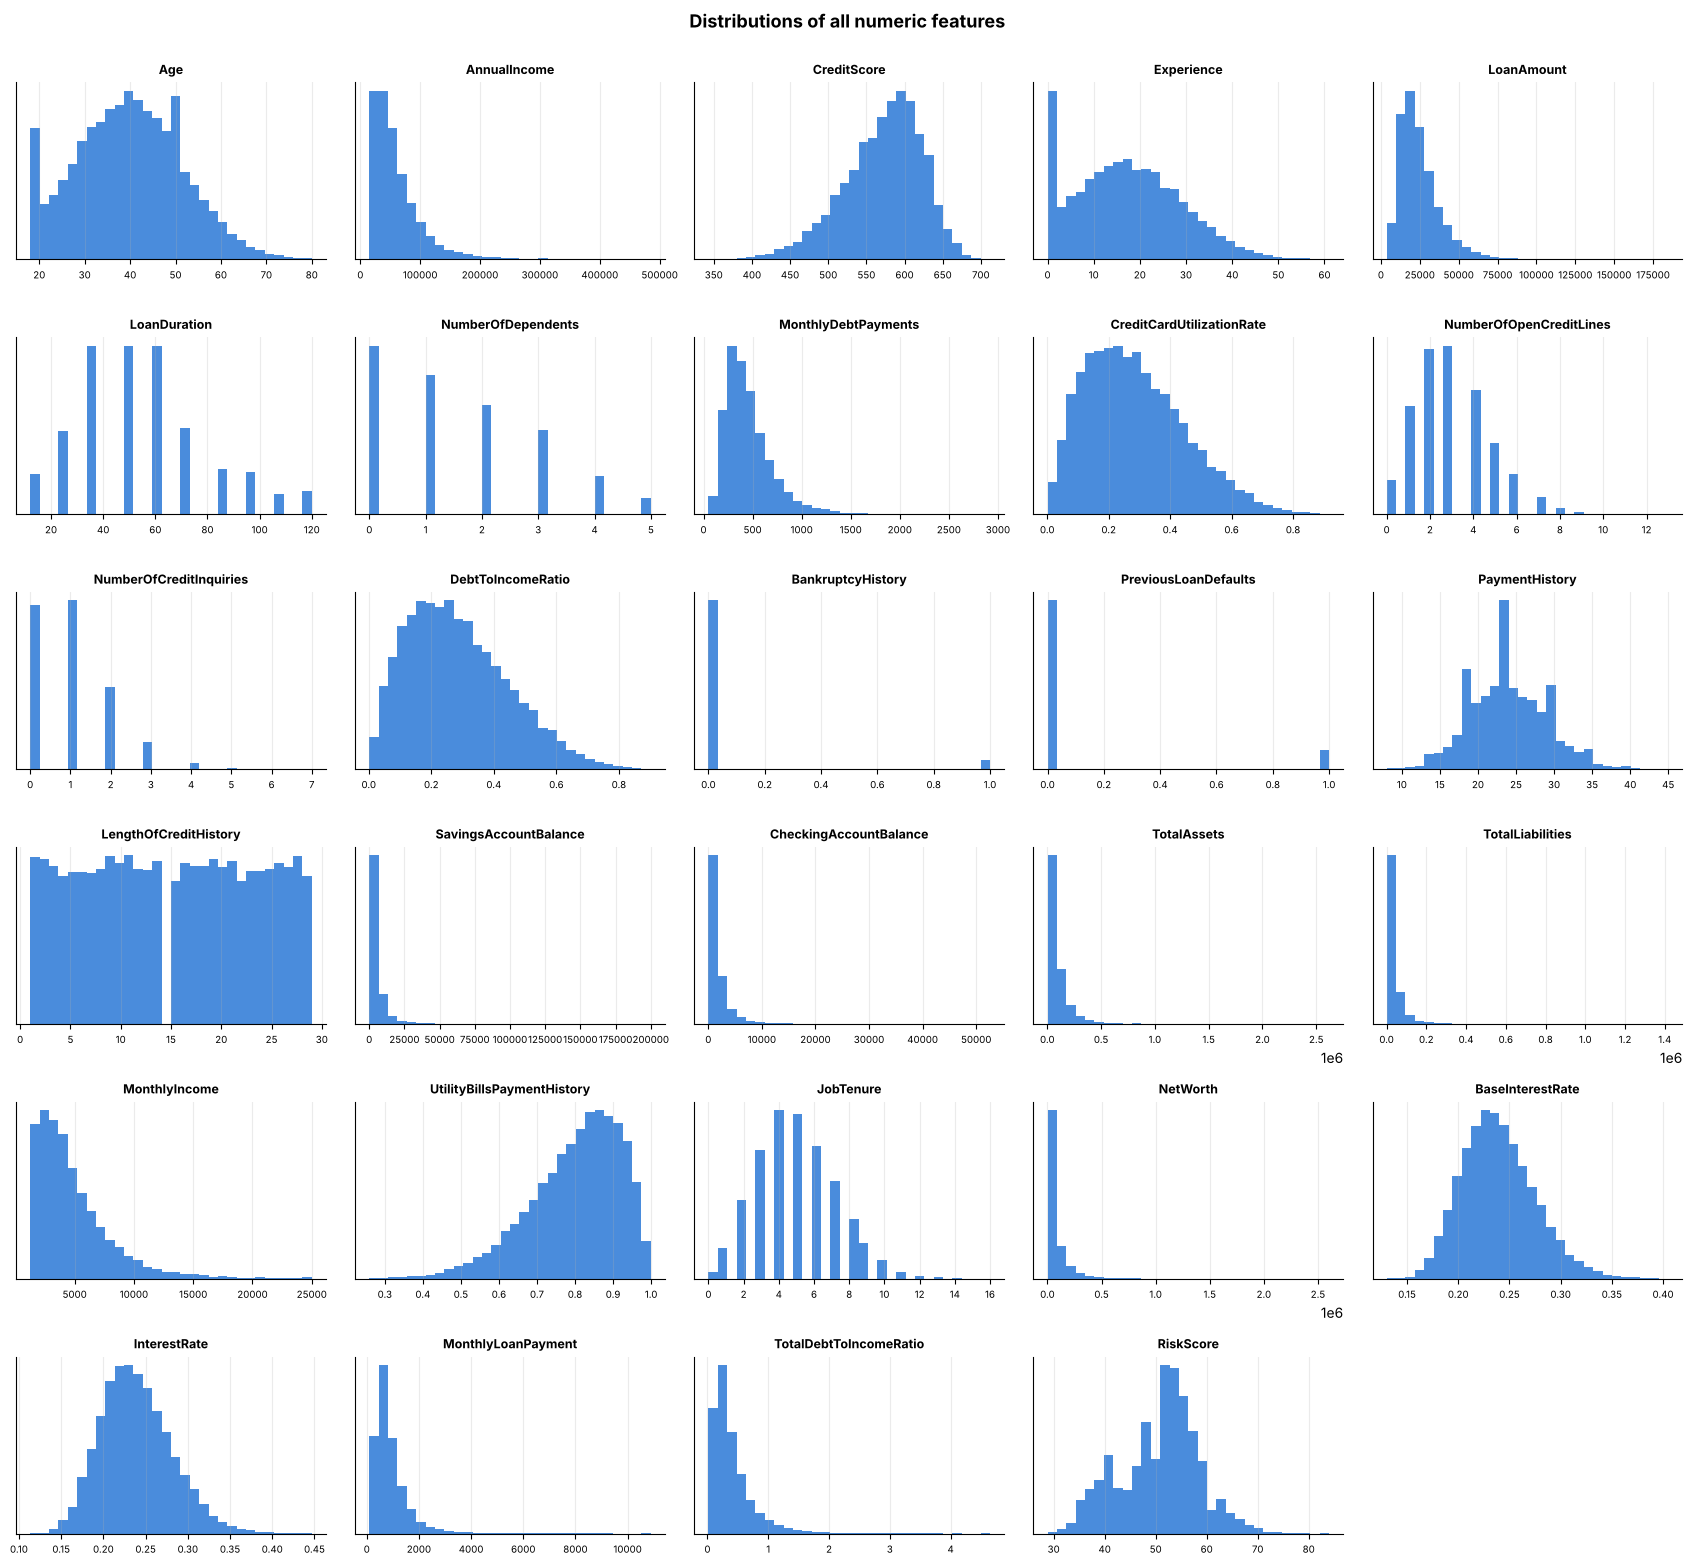

Most right-skewed features (skew > 2):
SavingsAccountBalance     6.10
TotalLiabilities          5.85
NetWorth                  5.60
TotalAssets               5.31
CheckingAccountBalance    4.75
BankruptcyHistory         4.02
MonthlyLoanPayment        3.08
PreviousLoanDefaults      2.67
TotalDebtToIncomeRatio    2.57
AnnualIncome              2.09


In [6]:
num_all = [c for c in df.select_dtypes("number").columns if c != TARGET]
n = len(num_all); ncols = 5; nrows = int(np.ceil(n/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 2.6*nrows))
for ax, c in zip(axes.ravel(), num_all):
    ax.hist(df[c].dropna(), bins=30, color=C_APP, alpha=0.85)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7); ax.set_yticks([])
for ax in axes.ravel()[n:]: ax.axis("off")
fig.suptitle("Distributions of all numeric features", y=1.0, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

skew = df[num_all].skew().sort_values(ascending=False)
print("Most right-skewed features (skew > 2):"); print(skew[skew > 2].round(2).to_string())

**Reading the histograms.** Money amounts (`LoanAmount`, `TotalAssets`, `TotalLiabilities`, `NetWorth`, `MonthlyDebtPayments`, balances) are strongly right-skewed with long tails, which hurts linear models unless scaled robustly or log-transformed. `CreditScore` has a hard ceiling near 712 and a left tail. `AnnualIncome` and `MonthlyIncome` pile up at a floor (see 2.5).

**Categorical features.**

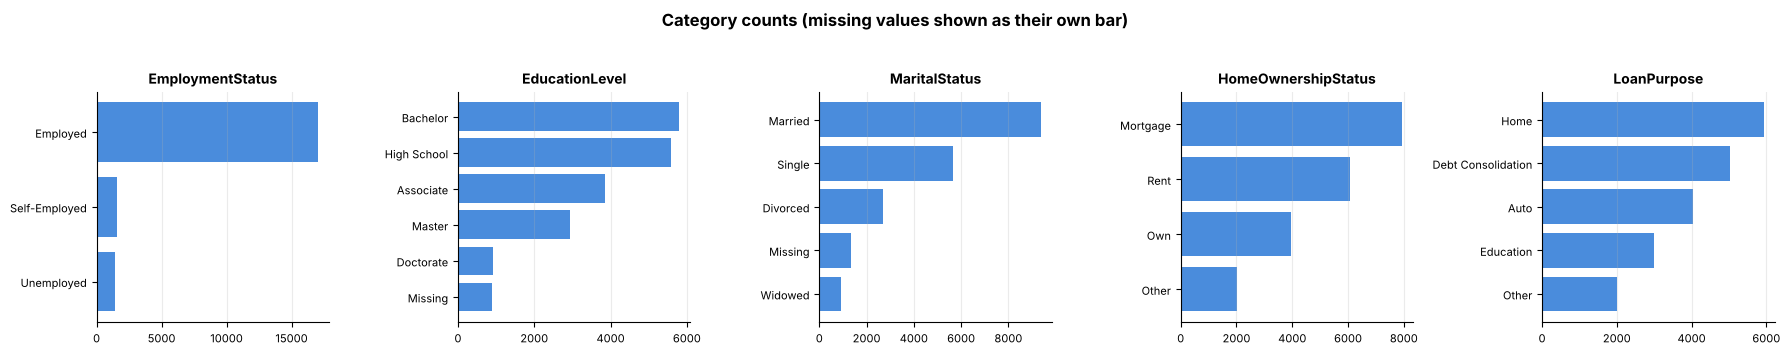

In [7]:
cat_cols_eda = ["EmploymentStatus", "EducationLevel", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, c in zip(axes, cat_cols_eda):
    s = df[c].fillna("Missing")
    order = s.value_counts().index
    ax.barh(order, s.value_counts().loc[order].values, color=C_APP, alpha=0.85)
    ax.invert_yaxis(); ax.set_title(c, fontsize=10); ax.tick_params(labelsize=8); ax.grid(axis="y", visible=False)
fig.suptitle("Category counts (missing values shown as their own bar)", y=1.03, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### 2.4 Relationships with the target and between features

**Approval rate by category.** Education stands out, and one group (`Missing` education) has an approval rate of exactly zero.

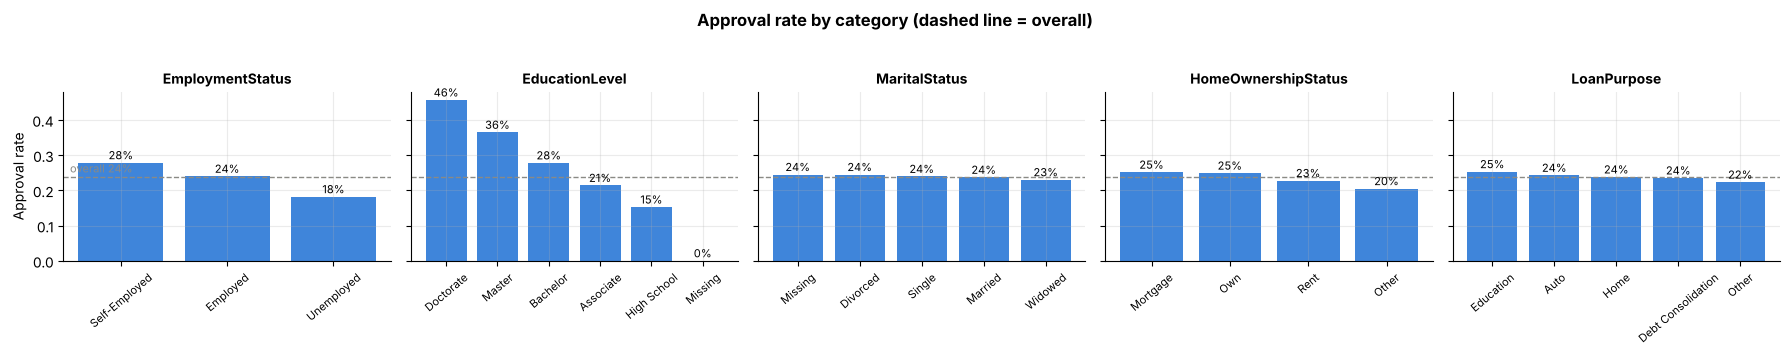

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
overall = df[TARGET].mean()
for ax, c in zip(axes, cat_cols_eda):
    rate = df.groupby(df[c].fillna("Missing"))[TARGET].mean().sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color=[C_DEC if v < overall*0.6 else C_APP for v in rate.values], alpha=0.9)
    ax.axhline(overall, color=C_NEUTRAL, ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.tick_params(axis="x", rotation=40, labelsize=8)
    for i, v in enumerate(rate.values): ax.text(i, v+0.01, f"{v:.0%}", ha="center", fontsize=8)
axes[0].set_ylabel("Approval rate"); axes[0].text(0.02, overall+0.012, f"overall {overall:.0%}", color=C_NEUTRAL, fontsize=8, transform=axes[0].get_yaxis_transform())
fig.suptitle("Approval rate by category (dashed line = overall)", y=1.03, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

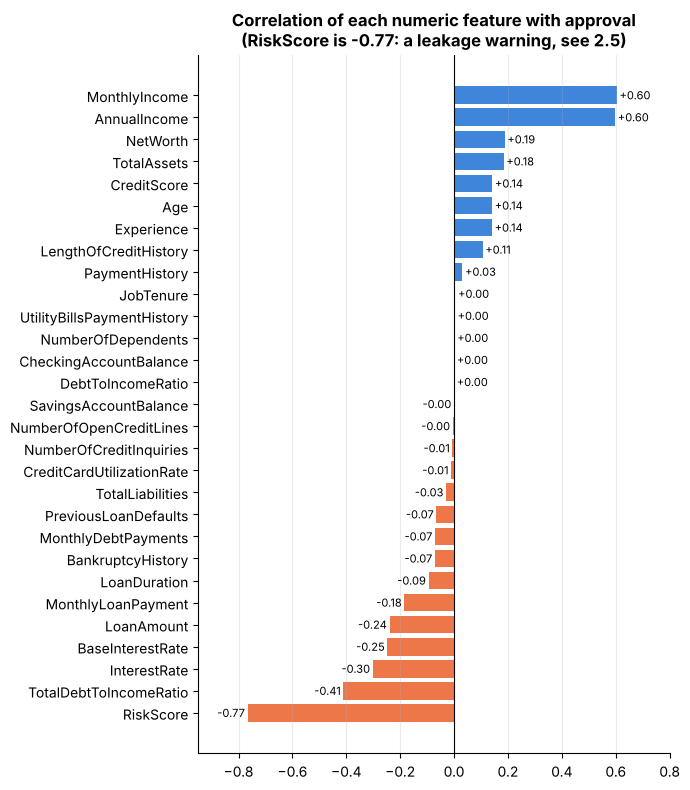

In [9]:
corr_t = df.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
colors = [C_DEC if v < 0 else C_APP for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors, alpha=0.9)
for i, (k, v) in enumerate(corr_t.items()):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlim(-0.95, 0.8)
ax.set_title("Correlation of each numeric feature with approval\n(RiskScore is -0.77: a leakage warning, see 2.5)")
plt.tight_layout(); plt.show()

Income dominates (`MonthlyIncome`/`AnnualIncome` about +0.60), followed by `TotalDebtToIncomeRatio` (-0.41) and `InterestRate` (-0.30). Many features (`DebtToIncomeRatio`, balances, `NumberOfDependents`, `UtilityBillsPaymentHistory`, `JobTenure`) have essentially **zero** linear relationship with approval. **`RiskScore` at -0.77 is the strongest of all, and that is a red flag, not a gift** (2.5).

**Feature-to-feature relationships.**

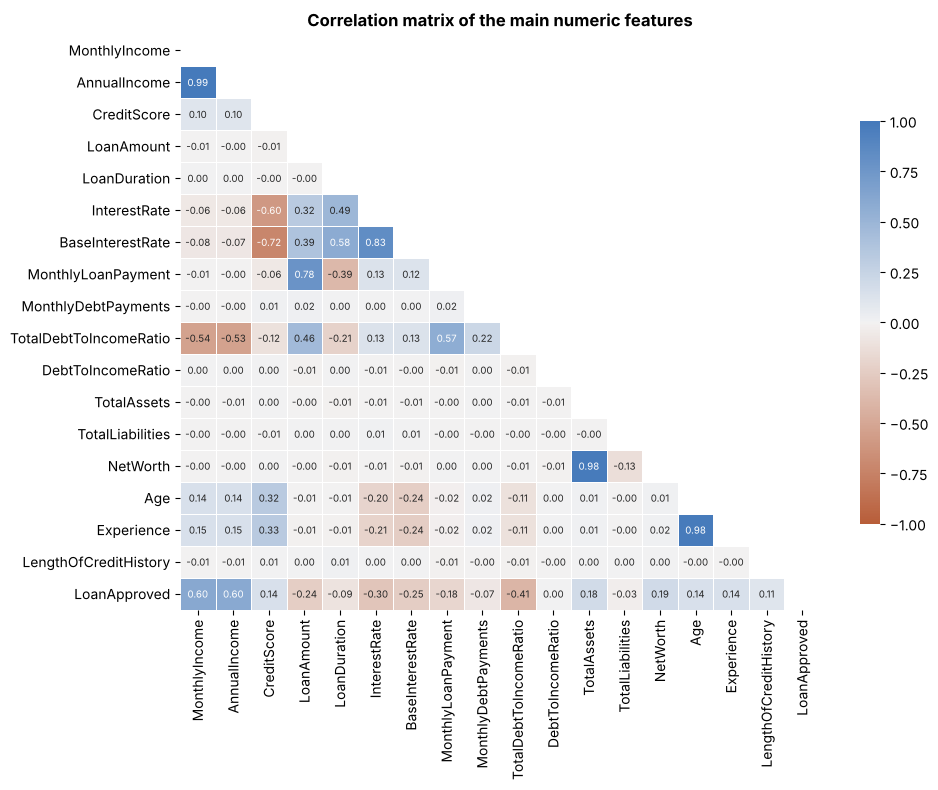

Highly collinear pairs (|r| > 0.8):


,level_0,level_1,r
18,AnnualIncome,MonthlyIncome,0.990
284,Experience,Age,0.983
245,NetWorth,TotalAssets,0.979
113,BaseInterestRate,InterestRate,0.835


In [10]:
heat_cols = ["MonthlyIncome", "AnnualIncome", "CreditScore", "LoanAmount", "LoanDuration", "InterestRate", "BaseInterestRate",
             "MonthlyLoanPayment", "MonthlyDebtPayments", "TotalDebtToIncomeRatio", "DebtToIncomeRatio", "TotalAssets",
             "TotalLiabilities", "NetWorth", "Age", "Experience", "LengthOfCreditHistory", TARGET]
corr = df[heat_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(25, 250, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix of the main numeric features"); ax.grid(False)
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack().rename("r").reset_index()
pairs = pairs[(pairs.r.abs() > 0.8) & (pairs.level_0 != TARGET) & (pairs.level_1 != TARGET)].sort_values("r", key=abs, ascending=False)
print("Highly collinear pairs (|r| > 0.8):"); display(pairs.round(3))

Several pairs are near-duplicates: `AnnualIncome` vs `MonthlyIncome` (monthly is annual / 12), `BaseInterestRate` vs `InterestRate`, `Age` vs `Experience`. Tree models do not care. For logistic regression, collinearity makes individual coefficients unstable, so we use **regularisation** and read coefficients with caution.

**How the strongest drivers separate the classes.**

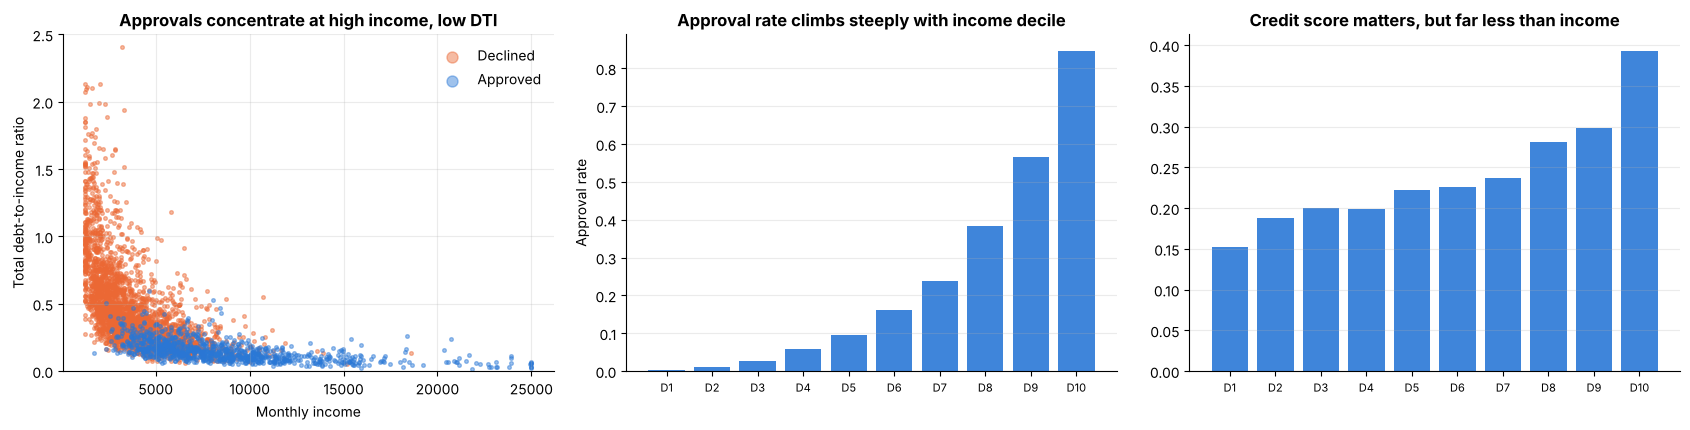

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

# (a) income vs total DTI, coloured by outcome
samp = df.sample(4000, random_state=RANDOM_STATE)
for lab, col, name in [(0, C_DEC, "Declined"), (1, C_APP, "Approved")]:
    s = samp[samp[TARGET] == lab]
    axes[0].scatter(s["MonthlyIncome"], s["TotalDebtToIncomeRatio"], s=7, alpha=0.45, color=col, label=name)
axes[0].set_ylim(0, 2.5); axes[0].set_xlabel("Monthly income"); axes[0].set_ylabel("Total debt-to-income ratio")
axes[0].set_title("Approvals concentrate at high income, low DTI"); axes[0].legend(markerscale=3)

# (b) approval rate by income decile
dec = pd.qcut(df["MonthlyIncome"], 10, duplicates="drop")
r = df.groupby(dec, observed=True)[TARGET].mean()
axes[1].bar(range(len(r)), r.values, color=C_APP, alpha=0.9)
axes[1].set_xticks(range(len(r))); axes[1].set_xticklabels([f"D{i+1}" for i in range(len(r))], fontsize=8)
axes[1].set_title("Approval rate climbs steeply with income decile"); axes[1].set_ylabel("Approval rate"); axes[1].grid(axis="x", visible=False)

# (c) approval rate by credit-score decile
dec = pd.qcut(df["CreditScore"], 10, duplicates="drop")
r = df.groupby(dec, observed=True)[TARGET].mean()
axes[2].bar(range(len(r)), r.values, color=C_APP, alpha=0.9)
axes[2].set_xticks(range(len(r))); axes[2].set_xticklabels([f"D{i+1}" for i in range(len(r))], fontsize=8)
axes[2].set_title("Credit score matters, but far less than income"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Income is by far the clearest separator. Credit score has a modest, positive effect. The scatter shows an almost "staircase" boundary in income and DTI, which suggests the historical decision follows a fairly smooth scoring rule, so we expect both linear and tree-based models to do well.

### 2.5 Data quality issues and their implications

In [12]:
quality = []
def add(issue, n, implication): quality.append({"issue": issue, "rows_affected": n, "implication": implication})

add("AnnualIncome stored as text with $ and commas", len(df), "Parsed to float (done above).")
add("AnnualIncome floored at $15,000", int((df.AnnualIncome == 15000).sum()), "Censored: true income is unknown for these applicants. Add a flag.")
add("AnnualIncome capped at $300,000", int((df.AnnualIncome == 300000).sum()), "Censored at the top; small group.")
mismatch = (df.AnnualIncome - df.MonthlyIncome*12).abs() > 1
add("AnnualIncome != 12 x MonthlyIncome", int(mismatch.sum()), "About 1% of incomes were inflated 1.5 to 2x after the fact (noise/outliers). MonthlyIncome looks like the reliable one.")
add("EducationLevel missing", int(df.EducationLevel.isna().sum()), "INFORMATIVE: every one was declined (see below).")
add("MaritalStatus missing", int(df.MaritalStatus.isna().sum()), "No relationship with the outcome: looks random (MCAR).")
add("SavingsAccountBalance missing", int(df.SavingsAccountBalance.isna().sum()), "No relationship with the outcome: looks random (MCAR).")
add("Experience > Age - 16", int((df.Experience > df.Age - 16).sum()), "None: age and experience are consistent.")
add("Duplicate rows", int(df.duplicated().sum()), "None.")
display(pd.DataFrame(quality))

print("\nApproval rate when the field is missing vs present")
miss = pd.DataFrame({c: df.groupby(df[c].isna())[TARGET].agg(["mean", "size"]).rename(index={False: "present", True: "missing"}).stack()
                     for c in ["EducationLevel", "MaritalStatus", "SavingsAccountBalance"]}).T
display(miss.round(3))

,issue,rows_affected,implication
0,AnnualIncome stored as text with $ and commas,20000,Parsed to float (done above).
1,"AnnualIncome floored at $15,000",584,Censored: true income is unknown for these app...
2,"AnnualIncome capped at $300,000",26,Censored at the top; small group.
3,AnnualIncome != 12 x MonthlyIncome,195,About 1% of incomes were inflated 1.5 to 2x af...
4,EducationLevel missing,901,INFORMATIVE: every one was declined (see below).
5,MaritalStatus missing,1331,No relationship with the outcome: looks random...
6,SavingsAccountBalance missing,572,No relationship with the outcome: looks random...
7,Experience > Age - 16,0,None: age and experience are consistent.
8,Duplicate rows,0,None.



Approval rate when the field is missing vs present


present          missing        
                         mean     size    mean    size
EducationLevel          0.250  19099.0   0.000   901.0
MaritalStatus           0.239  18669.0   0.245  1331.0
SavingsAccountBalance   0.238  19428.0   0.264   572.0

**Missing-value patterns and what they mean**

* `MaritalStatus` and `SavingsAccountBalance` are missing at similar approval rates to the rest of the data. This is consistent with *missing completely at random*, so a neutral fill is safe: a `"Missing"` category for marital status, and the median plus a missing-flag for savings.
* **`EducationLevel` is different.** All 901 applications with no education recorded were **declined**. That is *informative missingness*: either analysts decline incomplete files by policy, or the field is only filled in during approved-path processing. If we simply imputed the most common value we would **erase the strongest signal in the column**, so the pipeline imputes **and** adds an explicit missing-indicator. It also means the pattern is a *process artefact*: in production, a model leaning on it would auto-decline anyone who skips an optional field. We flag this in the recommendations.

**Leakage check: `RiskScore`.** The generator script in `archive.zip` computes `RiskScore` **after** the decision and multiplies it by 0.8 when `LoanApproved == 1`. The data agree: approved loans average ~40 vs ~54 for declined. The score contains the answer, so it **cannot be a feature** and is dropped before modeling.

In [13]:
print(df.groupby(TARGET)["RiskScore"].describe().round(1))
LEAKY = ["RiskScore"]

                count  mean  std   min   25%   50%   75%   max
LoanApproved                                                  
0             15220.0  54.1  5.3  38.0  50.0  54.0  57.0  84.0
1              4780.0  40.1  3.9  28.8  37.6  40.0  42.4  56.0


### 2.6 Feature understanding

| Group | Features | Treatment |
|---|---|---|
| **Numeric, skewed money** | `LoanAmount`, `MonthlyDebtPayments`, `SavingsAccountBalance`, `CheckingAccountBalance`, `TotalAssets`, `TotalLiabilities`, `NetWorth`, `MonthlyLoanPayment` | Scale (robust scaler is an option we tune); log-transform loan amount as an engineered feature |
| **Numeric, bounded ratios/rates** | `CreditCardUtilizationRate`, `DebtToIncomeRatio`, `TotalDebtToIncomeRatio`, `UtilityBillsPaymentHistory`, `InterestRate`, `BaseInterestRate` | Scale |
| **Numeric, counts/other** | `Age`, `Experience`, `CreditScore`, `LoanDuration`, `NumberOfDependents`, `NumberOfOpenCreditLines`, `NumberOfCreditInquiries`, `PaymentHistory`, `LengthOfCreditHistory`, `JobTenure`, `AnnualIncome`, `MonthlyIncome` | Median-impute (safety net), scale |
| **Binary** | `BankruptcyHistory` (Yes/No -> 0/1), `PreviousLoanDefaults` (0/1) | Pass through numeric |
| **Ordinal** | `EducationLevel`: High School < Associate < Bachelor < Master < Doctorate | Ordinal encode in that order; impute and add a missing-indicator |
| **Nominal** | `EmploymentStatus`, `MaritalStatus`, `HomeOwnershipStatus`, `LoanPurpose` | Fill missing with `"Missing"`, one-hot encode |
| **Excluded** | `RiskScore` | Target leakage |

**Feature-engineering opportunities** (built inside the pipeline so they are learned only from training folds and cannot leak):

* `LoanToIncome` = loan amount / annual income (affordability)
* `AssetsToLiabilities` = total assets / total liabilities (solvency)
* `IncomeRatio` = `AnnualIncome` / (12 x `MonthlyIncome`) (flags the ~1% inflated incomes)
* `IncomeAtFloor` flag (income censored at the minimum)
* `LogLoanAmount` (tames the long tail)

## 3. Data Preparation

### 3.1 Train/test split

We hold out **20% as a final test set** (stratified, so both sets keep the 24% approval rate). The test set is touched **once**, at the end. All model selection uses 5-fold stratified cross-validation inside the training set.

In [14]:
X = df.drop(columns=[TARGET] + LEAKY)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}  approval rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape}  approval rate {y_test.mean():.3f}")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (16000, 33)  approval rate 0.239
Test : (4000, 33)  approval rate 0.239


### 3.2 Preprocessing design

Each feature type gets its own flow, combined with a `ColumnTransformer`:

| Flow | Columns | Steps | Reason |
|---|---|---|---|
| **`num`** (a `FeatureUnion` of two branches) | all numeric + binary | **base**: median impute (+ missing-flag) -> scale; **eng**: engineered ratios/flags -> scale | The union keeps the original features *and* adds the engineered ones side by side. Scaling is required by logistic regression and harmless for trees. |
| **`edu`** (ordinal, a `FeatureUnion`) | `EducationLevel` | (most-frequent impute -> ordinal encode in true order) **+** (missing-indicator) -> scale | Preserves the order of qualifications *and* the "missing means declined" signal. |
| **`nom`** (nominal) | 4 categorical columns | fill `"Missing"` -> one-hot (`handle_unknown="ignore"`) | No natural order; unseen categories at prediction time must not crash. |

Everything is fitted **inside** the cross-validation folds via `Pipeline`, so imputation statistics and scaling never see validation data.

In [15]:
EDU_ORDER = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]
NOMINAL = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
ENG_NAMES = np.array(["LoanToIncome", "AssetsToLiabilities", "IncomeRatio", "IncomeAtFloor", "LogLoanAmount"])

def add_engineered(X):
    """Row-wise engineered features. No fitting, so it cannot leak across folds."""
    out = pd.DataFrame(index=X.index)
    out["LoanToIncome"] = X["LoanAmount"] / (X["MonthlyIncome"] * 12)
    out["AssetsToLiabilities"] = X["TotalAssets"] / X["TotalLiabilities"]
    out["IncomeRatio"] = X["AnnualIncome"] / (X["MonthlyIncome"] * 12)
    out["IncomeAtFloor"] = (X["MonthlyIncome"] <= 1250).astype(int)
    out["LogLoanAmount"] = np.log1p(X["LoanAmount"])
    return out

def build_preprocessor(columns, nominal=NOMINAL):
    """ColumnTransformer + Pipeline + FeatureUnion, built for whichever columns are available."""
    numeric = [c for c in columns if c not in nominal + ["EducationLevel"]]
    has_eng = {"LoanAmount", "MonthlyIncome", "AnnualIncome", "TotalAssets", "TotalLiabilities"} <= set(numeric)

    base = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler())])
    branches = [("base", base)]
    if has_eng:
        eng = Pipeline([("ratios", FunctionTransformer(add_engineered, feature_names_out=lambda t, names: ENG_NAMES)),
                        ("scale", StandardScaler())])
        branches.append(("eng", eng))
    num_flow = FeatureUnion(branches)

    edu_flow = Pipeline([
        ("union", FeatureUnion([
            ("ordinal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("encode", OrdinalEncoder(categories=[EDU_ORDER]))])),
            ("was_missing", MissingIndicator(features="all")),
        ])),
        ("scale", StandardScaler()),
    ])
    nom_flow = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Missing")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

    parts = [("num", num_flow, numeric)]
    if "EducationLevel" in columns: parts.append(("edu", edu_flow, ["EducationLevel"]))
    nom_present = [c for c in nominal if c in columns]
    if nom_present: parts.append(("nom", nom_flow, nom_present))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=True)

def make_pipeline(model, columns=None):
    columns = list(X_train.columns) if columns is None else columns
    return Pipeline([("prep", build_preprocessor(columns)), ("model", model)])

# Sanity check: the preprocessor on the training data
prep_check = build_preprocessor(list(X_train.columns))
Z = prep_check.fit_transform(X_train)
print("Transformed training matrix:", Z.shape, "| any NaN left:", bool(np.isnan(Z).any()))
names = prep_check.get_feature_names_out()
print("Examples:", list(names[:3]), "...", list(names[-12:]))

Transformed training matrix: (16000, 53) | any NaN left: False
Examples: ['num__base__Age', 'num__base__AnnualIncome', 'num__base__CreditScore'] ... ['nom__MaritalStatus_Missing', 'nom__MaritalStatus_Single', 'nom__MaritalStatus_Widowed', 'nom__HomeOwnershipStatus_Mortgage', 'nom__HomeOwnershipStatus_Other', 'nom__HomeOwnershipStatus_Own', 'nom__HomeOwnershipStatus_Rent', 'nom__LoanPurpose_Auto', 'nom__LoanPurpose_Debt Consolidation', 'nom__LoanPurpose_Education', 'nom__LoanPurpose_Home', 'nom__LoanPurpose_Other']


The transformed matrix has no missing values and includes the one-hot columns, the education ordinal + its missing flag, the savings missing flag, and the five engineered features.

## 4. Modeling

### 4.1 Metrics and validation strategy

* **Custom cost metric** `loan_cost` implements section 1.3. Wrapped with `make_scorer(greater_is_better=False)` so it can be used in cross-validation.
* **Scoring set:** ROC-AUC, average precision, F1, precision, recall and the custom cost, all computed in every fold.
* **Validation:** the stratified 5-fold CV defined above, on the training data only.

In [16]:
def loan_cost(y_true, y_pred, fp_cost=FP_COST, fn_cost=FN_COST):
    """Expected cost per application: wrong approvals (FP) cost more than wrong declines (FN)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (fp_cost * fp + fn_cost * fn) / len(y_true)

SCORING = {"roc_auc": "roc_auc", "avg_precision": "average_precision", "f1": "f1",
           "precision": "precision", "recall": "recall",
           "neg_cost": make_scorer(loan_cost, greater_is_better=False)}

# Trivial policies on the test set, for reference (they use no model)
n_te = len(y_test)
print(f"Decline everyone : cost/app = {loan_cost(y_test, np.zeros(n_te)):.3f}, accuracy = {1 - y_test.mean():.3f}")
print(f"Approve everyone : cost/app = {loan_cost(y_test, np.ones(n_te)):.3f}, accuracy = {y_test.mean():.3f}")

Decline everyone : cost/app = 0.239, accuracy = 0.761
Approve everyone : cost/app = 3.805, accuracy = 0.239


### 4.2 Baseline model comparison

We compare four candidates with cross-validation, each as a **complete pipeline** (preprocessing + model):

| Model | Why include it |
|---|---|
| **Dummy (stratified)** | Floor: what random guessing at the base rate achieves. |
| **Logistic regression** | Interpretable, regulator-friendly, fast; our "simple model" baseline. Needs the scaling we built in. |
| **Random forest** | Non-linear, handles interactions and skew with little tuning. |
| **Histogram gradient boosting** | Usually the strongest tabular learner; fast on 16k rows. |

In [17]:
candidates = {
    "Dummy (stratified)":   DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic regression":  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random forest":        RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist. gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = {}
for name, model in candidates.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    rows[name] = {k.replace("test_", ""): v.mean() for k, v in res.items() if k.startswith("test_")}
    rows[name]["cost_per_app"] = -rows[name].pop("neg_cost")
baseline_cv = pd.DataFrame(rows).T[["roc_auc", "avg_precision", "f1", "precision", "recall", "cost_per_app"]]
display(baseline_cv.round(3).style.background_gradient(cmap="Blues", subset=["roc_auc", "f1"]).background_gradient(cmap="Oranges_r", subset=["cost_per_app"]))

,roc_auc,avg_precision,f1,precision,recall,cost_per_app
Dummy (stratified),0.500000,0.239000,0.239000,0.239000,0.240000,1.097000
Logistic regression,0.995000,0.985000,0.928000,0.932000,0.924000,0.098000
Random forest,0.975000,0.931000,0.835000,0.872000,0.802000,0.189000
Hist. gradient boosting,0.991000,0.972000,0.900000,0.910000,0.891000,0.131000


All three real models are far above the dummy. The models are evaluated at the default 0.5 threshold here, so precision/recall/cost are not yet optimised; section 4.4 fixes that.

### 4.3 Hyperparameter tuning

We tune the two most useful candidates and show the *method* without a huge search:

* **Logistic regression: `GridSearchCV`** over the regularisation strength `C`, `class_weight`, **and two preprocessing choices** (scaler: `StandardScaler` vs `RobustScaler`, which matters because of the long tails; and the numeric imputation strategy). Parameters reach into the pipeline with the `step__substep__param` syntax.
* **Gradient boosting: `RandomizedSearchCV`** over learning rate, tree size and regularisation (12 random draws instead of a full grid, to keep time reasonable).

Both use `scoring=SCORING` (all six metrics tracked) and `refit="roc_auc"`: the final model is the one with the best ranking quality, and we can still inspect how each setting affects precision, recall and cost.

In [18]:
# --- Logistic regression: GridSearchCV, including preprocessing choices
lr_pipe = make_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
lr_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
    "prep__num__base__scale": [StandardScaler(), RobustScaler()],
    "prep__num__base__impute__strategy": ["median", "mean"],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
print("Best LR params :", {k: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in lr_search.best_params_.items()})
print(f"Best LR CV ROC-AUC: {lr_search.best_score_:.4f}   ({len(lr_search.cv_results_['params'])} combinations x 5 folds)")

Best LR params : {'model__C': 10, 'model__class_weight': None, 'prep__num__base__impute__strategy': 'median', 'prep__num__base__scale': 'StandardScaler'}
Best LR CV ROC-AUC: 0.9951   (32 combinations x 5 folds)


In [19]:
# --- Gradient boosting: RandomizedSearchCV
hgb_pipe = make_pipeline(HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.15,
                                                        n_iter_no_change=15, random_state=RANDOM_STATE))
hgb_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_depth": [3, 5, 7, None],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "model__max_iter": [200, 400],
}
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_dist, n_iter=12, scoring=SCORING, refit="roc_auc",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
hgb_search.fit(X_train, y_train)
print("Best HGB params:", hgb_search.best_params_)
print(f"Best HGB CV ROC-AUC: {hgb_search.best_score_:.4f}   (12 random draws x 5 folds)")

Best HGB params: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__max_iter': 400, 'model__max_depth': 7, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}
Best HGB CV ROC-AUC: 0.9921   (12 random draws x 5 folds)


**What did the parameters do?** The tables below track the effect of each setting.

In [20]:
def results_table(search, keep):
    r = pd.DataFrame(search.cv_results_)
    fmt = lambda v: type(v).__name__ if hasattr(v, "fit") else ("None" if v is None else v)
    out = pd.DataFrame({k.replace("model__", "").replace("prep__num__base__", ""): r["params"].map(lambda d, k=k: fmt(d[k])) for k in keep})
    out["roc_auc"] = r["mean_test_roc_auc"]; out["f1"] = r["mean_test_f1"]
    out["precision"] = r["mean_test_precision"]; out["recall"] = r["mean_test_recall"]
    out["cost@0.5"] = -r["mean_test_neg_cost"]
    return out

lr_keep = ["model__C", "model__class_weight", "prep__num__base__scale", "prep__num__base__impute__strategy"]
lr_res = results_table(lr_search, lr_keep)
print("Logistic regression: top 6 of 32 combinations by ROC-AUC")
display(lr_res.sort_values("roc_auc", ascending=False).head(6).round(4))

hgb_keep = ["model__learning_rate", "model__max_depth", "model__max_leaf_nodes", "model__min_samples_leaf", "model__l2_regularization", "model__max_iter"]
hgb_res = results_table(hgb_search, hgb_keep)
print("Gradient boosting: all 12 draws, best first")
display(hgb_res.sort_values("roc_auc", ascending=False).round(4))

Logistic regression: top 6 of 32 combinations by ROC-AUC


,C,class_weight,scale,impute__strategy,roc_auc,f1,precision,recall,cost@0.5
24,10.0,None,StandardScaler,median,0.9951,0.9280,0.9308,0.9252,0.1001
26,10.0,None,StandardScaler,mean,0.9951,0.9277,0.9310,0.9244,0.0999
27,10.0,None,RobustScaler,mean,0.9951,0.9280,0.9310,0.9249,0.0998
25,10.0,None,RobustScaler,median,0.9951,0.9284,0.9311,0.9257,0.0996
30,10.0,balanced,StandardScaler,mean,0.9951,0.9220,0.8791,0.9694,0.1667
28,10.0,balanced,StandardScaler,median,0.9951,0.9221,0.8793,0.9694,0.1664


Gradient boosting: all 12 draws, best first


,learning_rate,max_depth,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,roc_auc,f1,precision,recall,cost@0.5
10,0.05,7,15,50,1.0,400,0.9921,0.9092,0.9202,0.8985,0.1174
11,0.20,3,31,50,1.0,200,0.9921,0.9075,0.9186,0.8967,0.1197
5,0.20,3,15,100,0.0,200,0.9917,0.9061,0.9188,0.8938,0.1198
4,0.05,None,31,50,1.0,400,0.9914,0.9062,0.9171,0.8957,0.1218
1,0.10,5,63,50,1.0,400,0.9914,0.9048,0.9141,0.8957,0.1256
8,0.03,None,15,20,0.1,400,0.9914,0.9063,0.9168,0.8962,0.1220
7,0.20,7,31,100,0.1,400,0.9909,0.9042,0.9145,0.8941,0.1253
6,0.03,7,63,100,1.0,400,0.9908,0.9019,0.9182,0.8862,0.1216
0,0.10,5,31,20,0.0,400,0.9907,0.9028,0.9140,0.8920,0.1261
3,0.20,5,63,20,0.0,200,0.9905,0.9004,0.9111,0.8899,0.1301


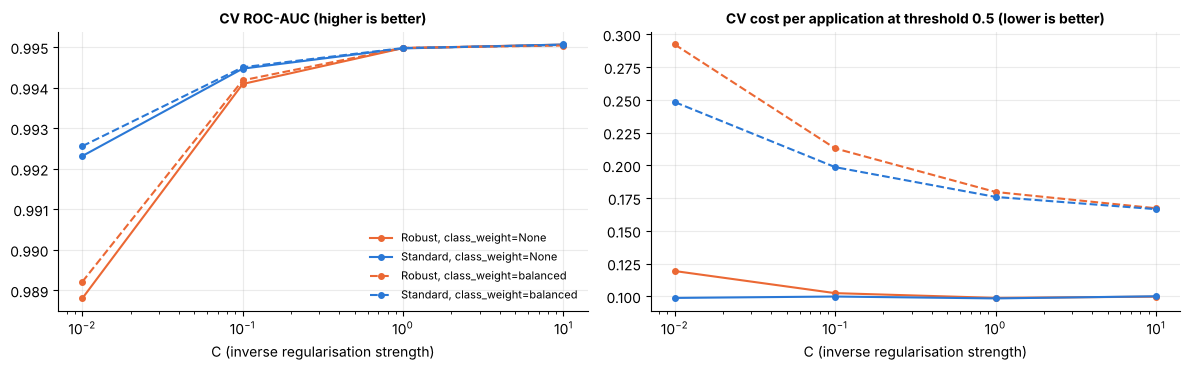

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
g = lr_res.groupby(["C", "class_weight", "scale"])[["roc_auc", "recall", "precision", "cost@0.5"]].mean().reset_index()
g["class_weight"] = g["class_weight"].astype(str)
for (cw, sc), s in g.groupby(["class_weight", "scale"]):
    ls = "-" if cw == "None" else "--"; col = C_APP if sc == "StandardScaler" else C_DEC
    axes[0].plot(s["C"], s["roc_auc"], ls, color=col, marker="o", ms=4, label=f"{sc.replace('Scaler','')}, class_weight={cw}")
    axes[1].plot(s["C"], s["cost@0.5"], ls, color=col, marker="o", ms=4)
for ax, t in zip(axes, ["CV ROC-AUC (higher is better)", "CV cost per application at threshold 0.5 (lower is better)"]):
    ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength)"); ax.set_title(t, fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the tuning results (trade-offs).**

* **Regularisation `C`:** AUC rises as regularisation is relaxed and flattens from `C = 1` upward; very strong regularisation (`C = 0.01`) clearly hurts. The best value (`C = 10`) is at the edge of our grid, so the next step would be to extend it (for example to 100) and confirm the plateau.
* **`class_weight="balanced"`** leaves AUC almost unchanged (ranking is unaffected) but, at the 0.5 threshold, buys recall at the price of precision (see the table: recall about 0.97 vs 0.93, precision about 0.88 vs 0.93) and a higher cost. Because we choose the threshold explicitly from the business cost in 4.4, we do not need class weights to do that job.
* **Scaler:** `RobustScaler` is noticeably worse than `StandardScaler` under strong regularisation, and the two converge once `C >= 1`. **Imputation strategy** makes no visible difference, because only `SavingsAccountBalance` has missing numeric values.
* **Gradient boosting:** the best draws use a moderate learning rate (0.05 to 0.2) with some L2 regularisation and enough trees; the worst draw (small trees, few iterations) is clearly under-fit (AUC 0.981 vs 0.992), so tuning matters, but even the best boosted model does not beat the tuned logistic regression. That is a useful finding: the historical decisions behave like a smooth, mostly linear scoring rule.

### 4.4 Choosing the final model and the decision threshold

We compare the two tuned models on cross-validation, apply a simple selection rule (**prefer the interpretable logistic regression unless boosting improves CV AUC by more than 0.005**), then choose the **decision threshold on out-of-fold predictions from the training data** that minimises the business cost. The test set stays untouched.

In [22]:
tuned_cv = pd.DataFrame({
    "Logistic regression (tuned)": {"roc_auc": lr_search.cv_results_["mean_test_roc_auc"][lr_search.best_index_],
                                    "avg_precision": lr_search.cv_results_["mean_test_avg_precision"][lr_search.best_index_]},
    "Hist. gradient boosting (tuned)": {"roc_auc": hgb_search.cv_results_["mean_test_roc_auc"][hgb_search.best_index_],
                                        "avg_precision": hgb_search.cv_results_["mean_test_avg_precision"][hgb_search.best_index_]},
}).T
display(tuned_cv.round(4))

gain = hgb_search.best_score_ - lr_search.best_score_
if gain > 0.005:
    final_name, final_search = "Hist. gradient boosting", hgb_search
else:
    final_name, final_search = "Logistic regression", lr_search
print(f"\nBoosting gain in CV AUC over logistic: {gain:+.4f}  ->  final model: {final_name}")
final_model = final_search.best_estimator_

,roc_auc,avg_precision
Logistic regression (tuned),0.9951,0.9851
Hist. gradient boosting (tuned),0.9921,0.9768



Boosting gain in CV AUC over logistic: -0.0030  ->  final model: Logistic regression


Cost-minimising threshold: 0.86  (cost/app 0.0617 vs 0.1001 at 0.5)


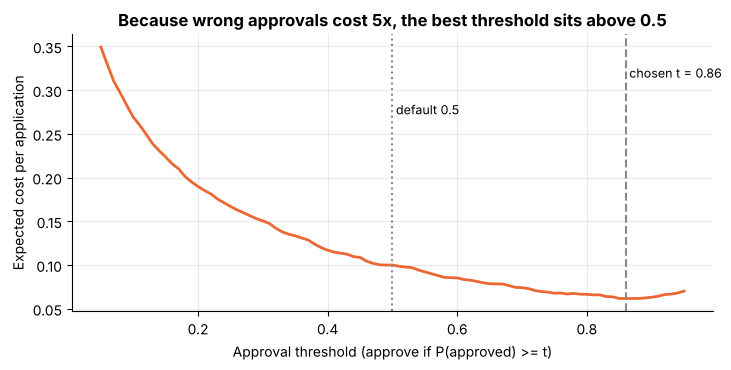

In [ ]:

oof = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
cost_curve = np.array([loan_cost(y_train, (oof >= t).astype(int)) for t in grid])
f1_curve = np.array([f1_score(y_train, (oof >= t).astype(int)) for t in grid])
best_t = float(grid[cost_curve.argmin()])
print(f"Cost-minimising threshold: {best_t:.2f}  (cost/app {cost_curve.min():.4f} vs {loan_cost(y_train, (oof>=0.5).astype(int)):.4f} at 0.5)")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(grid, cost_curve, color=C_DEC, lw=2, label="Cost per application")
ax.axvline(best_t, color=C_NEUTRAL, ls="--"); ax.axvline(0.5, color=C_NEUTRAL, ls=":")
ax.text(best_t, cost_curve.max()*0.9, f" chosen t = {best_t:.2f}", fontsize=9); ax.text(0.5, cost_curve.max()*0.78, " default 0.5", fontsize=9)
ax.set_xlabel("Approval threshold (approve if P(approved) >= t)"); ax.set_ylabel("Expected cost per application")
ax.set_title("Because wrong approvals cost 5x, the best threshold sits above 0.5")
plt.tight_layout(); plt.show()

Raising the threshold makes the model approve only when it is more certain, which trades some recall for fewer expensive false approvals. That is exactly the "risk appetite dial" Risk wants. If the 5:1 cost ratio changes, re-running this cell moves the threshold.

## 5. Evaluation

### 5.1 Final performance on the held-out test set

In [24]:
p_test = final_model.predict_proba(X_test)[:, 1]
yhat = (p_test >= best_t).astype(int)
yhat_05 = (p_test >= 0.5).astype(int)

def summarise(y_true, p, pred):
    return {"ROC-AUC": roc_auc_score(y_true, p), "Avg precision": average_precision_score(y_true, p),
            "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "Cost / application": loan_cost(y_true, pred)}

lr_final_p = lr_search.best_estimator_.predict_proba(X_test)[:, 1]
test_table = pd.DataFrame({
    f"{final_name} @ t={best_t:.2f} (final)": summarise(y_test, p_test, yhat),
    f"{final_name} @ t=0.50": summarise(y_test, p_test, yhat_05),
    "Decline everyone": summarise(y_test, np.zeros(n_te), np.zeros(n_te, dtype=int)),
    "Approve everyone": summarise(y_test, np.ones(n_te), np.ones(n_te, dtype=int)),
}).T
display(test_table.round(3))

best_trivial = min(loan_cost(y_test, np.zeros(n_te)), loan_cost(y_test, np.ones(n_te)))
final_cost = loan_cost(y_test, yhat)
print(f"Cost per application: final model {final_cost:.3f} vs best trivial policy {best_trivial:.3f} "
      f"-> {1 - final_cost/best_trivial:.0%} reduction")

targets = {"ROC-AUC >= 0.90": test_table.iloc[0]["ROC-AUC"] >= 0.90,
           "Precision >= 0.80": test_table.iloc[0]["Precision"] >= 0.80,
           "Recall >= 0.70": test_table.iloc[0]["Recall"] >= 0.70,
           "Cost <= 40% of best trivial": final_cost <= 0.40*best_trivial}
print("\nTargets from section 1.5:"); [print(f"  {'MET ' if v else 'MISSED'}  {k}") for k, v in targets.items()];

,ROC-AUC,Avg precision,Accuracy,Precision,Recall,F1,Cost / application
Logistic regression @ t=0.86 (final),0.995,0.985,0.950,0.977,0.811,0.886,0.068
Logistic regression @ t=0.50,0.995,0.985,0.967,0.932,0.929,0.930,0.098
Decline everyone,0.500,0.239,0.761,0.000,0.000,0.000,0.239
Approve everyone,0.500,0.239,0.239,0.239,1.000,0.386,3.805


Cost per application: final model 0.068 vs best trivial policy 0.239 -> 72% reduction

Targets from section 1.5:
  MET   ROC-AUC >= 0.90
  MET   Precision >= 0.80
  MET   Recall >= 0.70
  MET   Cost <= 40% of best trivial


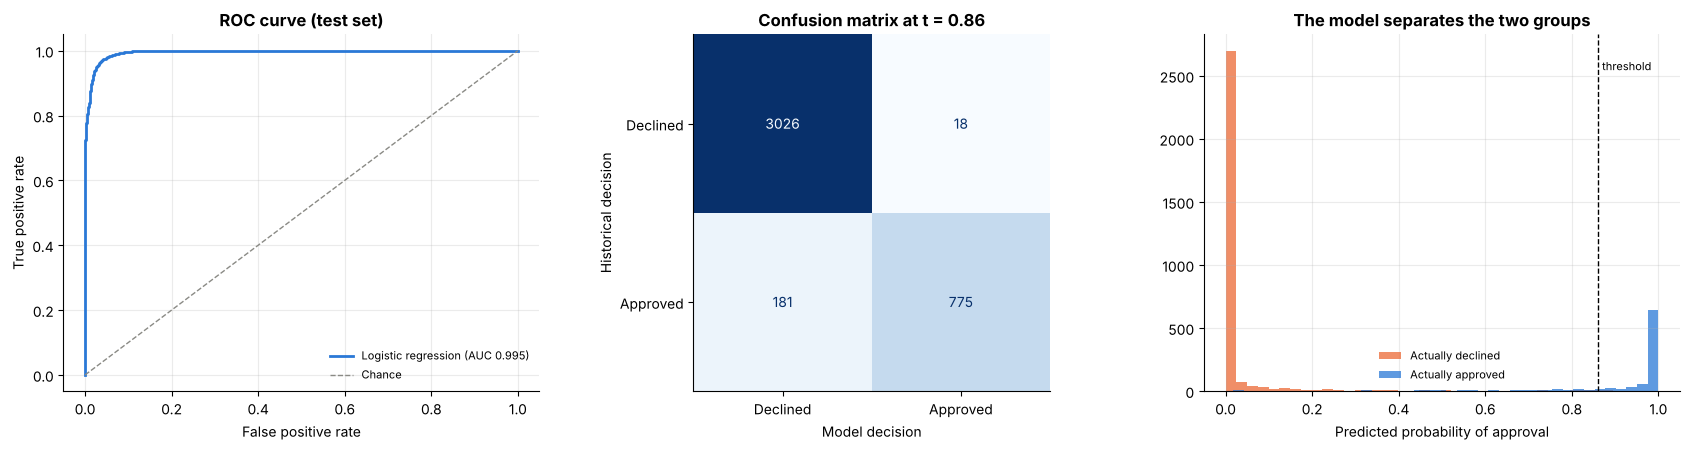

TN=3026  FP=18  FN=181  TP=775


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))


fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=C_APP, lw=2, label=f"{final_name} (AUC {roc_auc_score(y_test, p_test):.3f})")
if final_name != "Logistic regression":
    f2, t2, _ = roc_curve(y_test, lr_final_p)
    axes[0].plot(f2, t2, color=C_DEC, lw=2, label=f"Logistic regression (AUC {roc_auc_score(y_test, lr_final_p):.3f})")
axes[0].plot([0, 1], [0, 1], color=C_NEUTRAL, ls="--", lw=1, label="Chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(loc="lower right", fontsize=8)


cm = confusion_matrix(y_test, yhat)
ConfusionMatrixDisplay(cm, display_labels=["Declined", "Approved"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].grid(False); axes[1].set_title(f"Confusion matrix at t = {best_t:.2f}")
axes[1].set_xlabel("Model decision"); axes[1].set_ylabel("Historical decision")


axes[2].hist(p_test[y_test == 0], bins=40, alpha=0.75, color=C_DEC, label="Actually declined")
axes[2].hist(p_test[y_test == 1], bins=40, alpha=0.75, color=C_APP, label="Actually approved")
axes[2].axvline(best_t, color="black", ls="--", lw=1); axes[2].text(best_t+0.01, axes[2].get_ylim()[1]*0.9, "threshold", fontsize=8)
axes[2].set_xlabel("Predicted probability of approval"); axes[2].set_title("The model separates the two groups"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
tn, fp, fn_, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn_}  TP={tp}")

### 5.1b How the model could be used: a triage policy

A single approve/decline threshold is not the only option. A safer first deployment uses **three bands**: auto-approve only when the model is very sure, auto-decline when it is very sure, and send everything in between to a human analyst. The band edges are a business choice; the table shows what each band contains on the test set.

In [26]:
LOW = 0.10
band = pd.cut(p_test, [-0.001, LOW, best_t, 1.001], labels=[f"Auto-decline (p < {LOW:.2f})", f"Analyst review ({LOW:.2f} <= p < {best_t:.2f})", f"Auto-approve (p >= {best_t:.2f})"])
tri = pd.DataFrame({"band": band, "y": y_test.values}).groupby("band", observed=True).agg(applications=("y", "size"), historically_approved=("y", "sum"))
tri["share_of_applications"] = tri.applications / tri.applications.sum()
tri["historical_approval_rate"] = tri.historically_approved / tri.applications
display(tri.round(3))
auto_share = tri.share_of_applications.iloc[[0, 2]].sum()
print(f"Share of applications decided automatically: {auto_share:.1%}")
band_s = pd.Series(band.astype(str))
print(f"Errors among auto-decisions: {int((band_s.str.startswith('Auto-approve').values & (y_test.values == 0)).sum())} wrong approvals, "
      f"{int((band_s.str.startswith('Auto-decline').values & (y_test.values == 1)).sum())} wrong declines")

,applications,historically_approved,share_of_applications,historical_approval_rate
band,,,,
Auto-decline (p < 0.10),2844,11,0.711,0.004
Analyst review (0.10 <= p < 0.86),363,170,0.091,0.468
Auto-approve (p >= 0.86),793,775,0.198,0.977


Share of applications decided automatically: 90.9%
Errors among auto-decisions: 18 wrong approvals, 11 wrong declines


### 5.2 Performance across data segments

A model can look good overall and still fail for a subgroup. We compute the same metrics within segments of the **test set**: how often the model approves vs how often the historical process did (*approval rate gap*), plus precision, recall and cost. Groups with fewer than about 30 positives give noisy recall, so read them with care.

In [27]:
seg = X_test.copy()
seg["y"] = y_test.values; seg["p"] = p_test; seg["pred"] = yhat
seg["AgeBand"] = pd.cut(seg["Age"], [17, 29, 39, 49, 59, 100], labels=["18-29", "30-39", "40-49", "50-59", "60+"])
seg["IncomeQuartile"] = pd.qcut(seg["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
seg["CreditBand"] = pd.cut(seg["CreditScore"], [0, 540, 580, 610, 900], labels=["<=540", "541-580", "581-610", ">610"])
for c in ["EducationLevel", "MaritalStatus"]: seg[c] = seg[c].fillna("Missing")

def seg_table(col):
    rows = []
    for g, d in seg.groupby(col, observed=True):
        pos = d.y.sum()
        rows.append({"segment": g, "n": len(d), "actual_approval": d.y.mean(), "model_approval": d.pred.mean(),
                     "gap": d.pred.mean() - d.y.mean(),
                     "precision": precision_score(d.y, d.pred, zero_division=0) if d.pred.sum() else np.nan,
                     "recall": recall_score(d.y, d.pred) if pos else np.nan,
                     "auc": roc_auc_score(d.y, d.p) if 0 < pos < len(d) else np.nan,
                     "cost_per_app": loan_cost(d.y, d.pred)})
    return pd.DataFrame(rows).set_index("segment")

SEG_COLS = ["EmploymentStatus", "EducationLevel", "AgeBand", "IncomeQuartile", "CreditBand", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
seg_tables = {c: seg_table(c) for c in SEG_COLS}
for c in ["EmploymentStatus", "EducationLevel", "IncomeQuartile"]:
    print(f"--- {c}"); display(seg_tables[c].round(3))

--- EmploymentStatus


,n,actual_approval,model_approval,gap,precision,recall,auc,cost_per_app
segment,,,,,,,,
Employed,3402,0.242,0.200,-0.043,0.982,0.809,0.995,0.064
Self-Employed,311,0.264,0.241,-0.023,0.947,0.866,0.993,0.100
Unemployed,287,0.174,0.136,-0.038,0.949,0.740,0.993,0.080


--- EducationLevel


,n,actual_approval,model_approval,gap,precision,recall,auc,cost_per_app
segment,,,,,,,,
Associate,782,0.207,0.161,-0.046,0.952,0.741,0.993,0.092
Bachelor,1163,0.279,0.236,-0.043,0.982,0.831,0.995,0.069
Doctorate,156,0.442,0.397,-0.045,1.000,0.899,0.990,0.045
High School,1086,0.153,0.120,-0.033,0.977,0.765,0.996,0.050
Master,620,0.377,0.323,-0.055,0.980,0.838,0.993,0.094
Missing,193,0.000,0.000,0.000,NaN,NaN,NaN,0.000


--- IncomeQuartile


,n,actual_approval,model_approval,gap,precision,recall,auc,cost_per_app
segment,,,,,,,,
Q1 (lowest),1000,0.014,0.012,-0.002,0.833,0.714,0.998,0.014
Q2,1000,0.072,0.048,-0.024,0.958,0.639,0.994,0.036
Q3,1000,0.225,0.166,-0.059,0.958,0.707,0.986,0.101
Q4 (highest),1000,0.645,0.567,-0.078,0.988,0.868,0.991,0.120


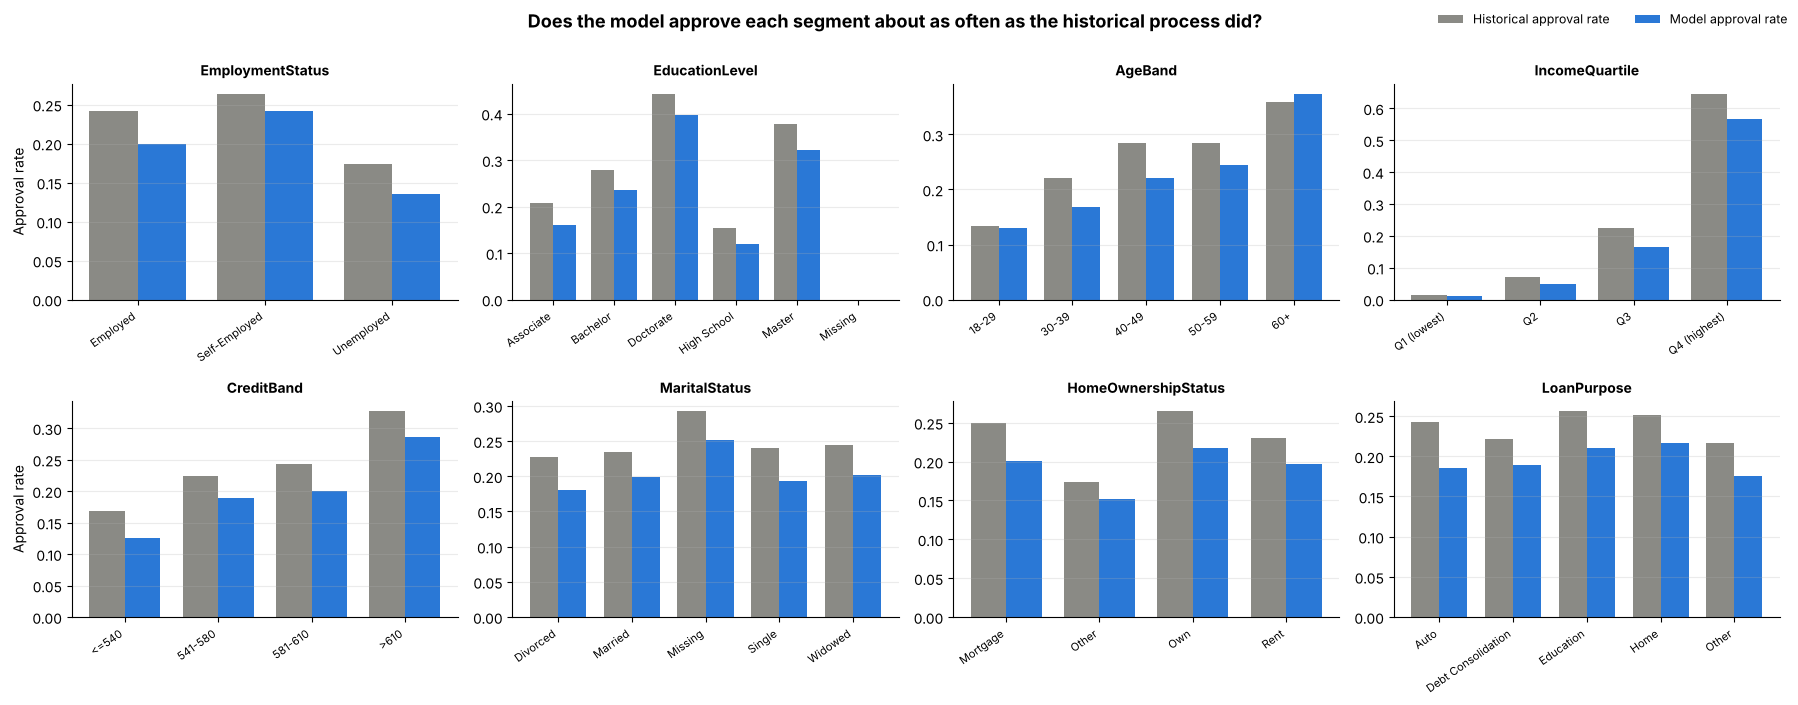

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), SEG_COLS):
    t = seg_tables[c]; x = np.arange(len(t)); w = 0.38
    ax.bar(x - w/2, t["actual_approval"], w, color=C_NEUTRAL, label="Historical approval rate")
    ax.bar(x + w/2, t["model_approval"], w, color=C_APP, label="Model approval rate")
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=35, ha="right", fontsize=8); ax.set_title(c, fontsize=10)
    ax.grid(axis="x", visible=False)
h_, l_ = axes[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc="upper right", ncol=2, fontsize=9)
axes[0, 0].set_ylabel("Approval rate"); axes[1, 0].set_ylabel("Approval rate")
fig.suptitle("Does the model approve each segment about as often as the historical process did?", y=1.0, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

### 5.3 Bias, fairness and limitations

Some features describe **who** the applicant is rather than **how risky** they are: `Age`, `MaritalStatus`, `NumberOfDependents`, and (arguably) `EducationLevel`. Fair-lending rules in many jurisdictions restrict or prohibit using age and marital status in credit decisions (for example the US ECOA). Compliance must confirm what applies to FinTech Innovations. We run two checks:

1. **Disparate-impact ratio** = model approval rate of a group / highest group approval rate (the common "four-fifths rule" flags ratios below 0.80), shown next to the *historical* ratio, so we can see whether the model **adds** disparity or only **inherits** it.
2. **Ablation:** how much predictive power do we lose if we remove `Age` and `MaritalStatus`? And what if we remove `InterestRate`/`BaseInterestRate`, which are only known once a loan is priced?

In [29]:
def di_table(col):
    t = seg_tables[col][["n", "actual_approval", "model_approval"]].copy()
    t = t[t.n >= 30]
    t["historical_DI"] = t.actual_approval / t.actual_approval.max()
    t["model_DI"] = t.model_approval / t.model_approval.max()
    return t.round(3)

for c in ["AgeBand", "MaritalStatus"]:
    print(f"--- {c}"); display(di_table(c))

--- AgeBand


,n,actual_approval,model_approval,historical_DI,model_DI
segment,,,,,
18-29,773,0.133,0.131,0.372,0.350
30-39,1227,0.220,0.168,0.614,0.449
40-49,1197,0.284,0.221,0.792,0.590
50-59,605,0.284,0.245,0.793,0.655
60+,198,0.359,0.374,1.000,1.000


--- MaritalStatus


,n,actual_approval,model_approval,historical_DI,model_DI
segment,,,,,
Divorced,506,0.227,0.180,0.778,0.717
Married,1911,0.234,0.199,0.801,0.792
Missing,267,0.292,0.251,1.000,1.000
Single,1152,0.240,0.193,0.820,0.768
Widowed,164,0.244,0.201,0.835,0.802


In [ ]:

base_model = final_model.named_steps["model"]
def fit_eval(drop):
    cols = [c for c in X_train.columns if c not in drop]
    pipe = make_pipeline(clone(base_model), columns=cols).fit(X_train[cols], y_train)
    p = pipe.predict_proba(X_test[cols])[:, 1]
    return {"ROC-AUC": roc_auc_score(y_test, p), "Avg precision": average_precision_score(y_test, p),
            "Cost @ chosen t": loan_cost(y_test, (p >= best_t).astype(int)), "features": len(cols)}

ablation = pd.DataFrame({
    "All features": fit_eval([]),
    "Without Age, MaritalStatus": fit_eval(["Age", "MaritalStatus"]),
    "Without Age, MaritalStatus, NumberOfDependents": fit_eval(["Age", "MaritalStatus", "NumberOfDependents"]),
    "Without InterestRate, BaseInterestRate": fit_eval(["InterestRate", "BaseInterestRate"]),
}).T
display(ablation.round(4))

,ROC-AUC,Avg precision,Cost @ chosen t,features
All features,0.9950,0.9848,0.0678,33.0
"Without Age, MaritalStatus",0.9950,0.9849,0.0668,31.0
"Without Age, MaritalStatus, NumberOfDependents",0.9950,0.9848,0.0665,30.0
"Without InterestRate, BaseInterestRate",0.9799,0.9433,0.1192,31.0


### 5.4 Which features matter?

We use **permutation importance** on the held-out test set: shuffle one original column at a time and measure the drop in ROC-AUC. It works on the whole pipeline, so one-hot columns and engineered features are credited to the original column they came from. We then add **partial-dependence** curves for the top drivers (to see the *direction* of the effect) and the **logistic regression coefficients** (an independent, interpretable view).

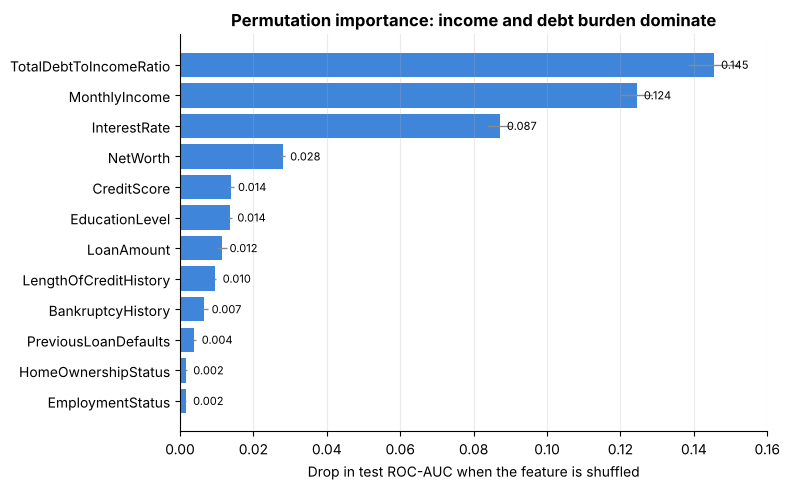

,feature,importance,std
0,TotalDebtToIncomeRatio,0.1454,0.0070
1,MonthlyIncome,0.1244,0.0043
2,InterestRate,0.0871,0.0033
3,NetWorth,0.0280,0.0007
4,CreditScore,0.0138,0.0009
5,EducationLevel,0.0136,0.0004
6,LoanAmount,0.0115,0.0013
7,LengthOfCreditHistory,0.0096,0.0003
8,BankruptcyHistory,0.0066,0.0009
9,PreviousLoanDefaults,0.0039,0.0005


Features with ~zero importance (<0.0005): ['MonthlyLoanPayment', 'Age', 'Experience', 'LoanDuration', 'LoanPurpose', 'TotalAssets', 'SavingsAccountBalance', 'MaritalStatus', 'DebtToIncomeRatio', 'UtilityBillsPaymentHistory', 'TotalLiabilities', 'MonthlyDebtPayments', 'NumberOfOpenCreditLines', 'CheckingAccountBalance', 'NumberOfDependents', 'JobTenure', 'NumberOfCreditInquiries', 'CreditCardUtilizationRate']


In [31]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std}).sort_values("importance", ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.importance, xerr=top["std"], color=C_APP, alpha=0.9, error_kw={"lw": 1, "ecolor": C_NEUTRAL})
for i, v in enumerate(top.importance): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance: income and debt burden dominate")
plt.tight_layout(); plt.show()
display(imp.head(10).round(4).reset_index(drop=True))
print("Features with ~zero importance (<0.0005):", list(imp[imp.importance < 0.0005].feature))

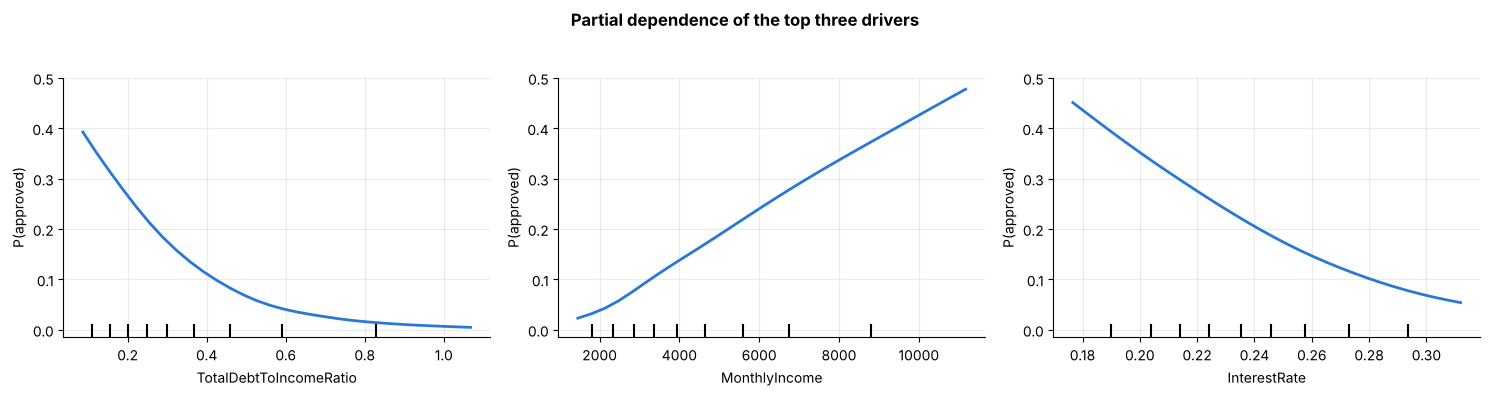

In [32]:
top3 = list(imp.head(3).feature)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
PartialDependenceDisplay.from_estimator(final_model, X_test.sample(2000, random_state=RANDOM_STATE), top3, ax=ax,
                                        line_kw={"color": C_APP, "lw": 2}, grid_resolution=30)
for a in ax: a.set_ylabel("P(approved)")
fig.suptitle("Partial dependence of the top three drivers", y=1.03, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

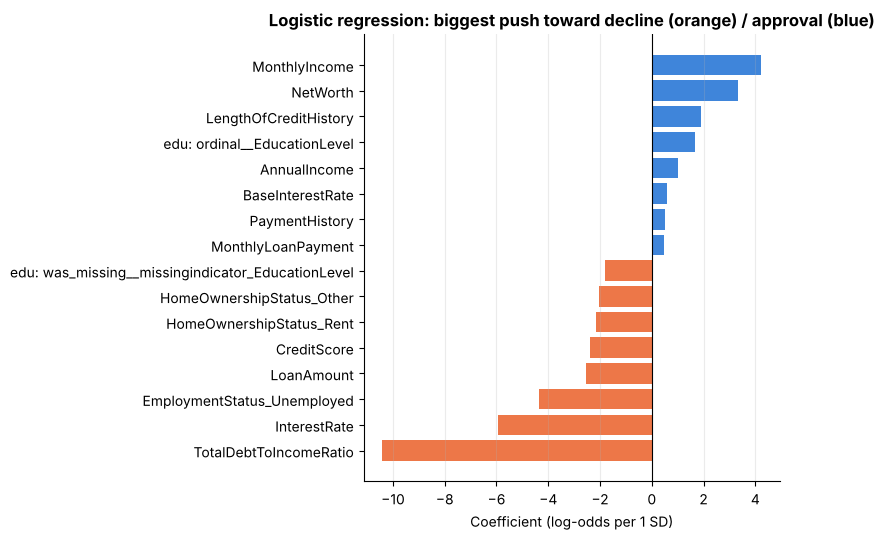

In [ ]:

lr_best = lr_search.best_estimator_
coef_names = lr_best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_best.named_steps["model"].coef_[0], index=coef_names)
coefs.index = [i.replace("num__base__", "").replace("num__eng__", "eng: ").replace("nom__", "").replace("edu__", "edu: ") for i in coefs.index]
sel = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(sel.index, sel.values, color=[C_DEC if v < 0 else C_APP for v in sel.values], alpha=0.9)
ax.axvline(0, color="black", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Coefficient (log-odds per 1 SD)"); ax.set_title("Logistic regression: biggest push toward decline (orange) / approval (blue)")
plt.tight_layout(); plt.show()

## 6. Conclusion

### 6.1 Executive summary (for business stakeholders)

**What we did.** We built an automated loan-decision model from 20,000 past applications, tested it on 4,000 applications it had never seen, and chose its settings with cross-validation on the rest.

**What we found.**

* **The model works.** On unseen applications it ranks approvable above non-approvable applicants almost perfectly (ROC-AUC 0.995). At the chosen setting, of 4,000 applications it made 18 wrong approvals and 181 wrong declines, and 775 correct approvals.
* **It meets every target we set up front** (ROC-AUC >= 0.90, precision >= 0.80, recall >= 0.70, cost <= 40% of the best trivial policy): precision 0.977, recall 0.811, F1 0.886, and an expected cost of 0.068 per application against 0.239 for "decline everyone", a **72% reduction**.
* **The simple model won.** The tuned logistic regression (CV AUC 0.9951) beat tuned gradient boosting (0.9921) and the random forest (0.975, untuned). That is good news for explainability and regulators: decisions can be explained with a handful of factors.
* **What drives decisions:** (1) total debt-to-income ratio, (2) monthly income, (3) interest rate, then net worth, credit score, education, loan amount and credit-history length. Higher income and lower debt burden raise the approval chance; higher quoted interest rates, larger loans and unemployment lower it.
* **Triage is practical:** with an auto-decline band (p < 0.10), an auto-approve band (p >= 0.86) and analyst review in between, **90.9%** of applications are decided automatically with 18 wrong approvals and 11 wrong declines on the test set (out of 3,637 automatic decisions); the **9.1%** in the middle are about 47% historically approved, i.e. genuinely borderline, and are the right place for human judgement.

**What to be careful about.**

* **This is a copy of past decisions, not a default predictor.** It will repeat any mistakes or bias in them.
* **A missing education field means automatic decline** in the history (all 901 cases). The model learned that rule. It is a process artefact, not a measure of risk.
* **Age disparity:** the historical approval rate rises steadily with age, and the model keeps that pattern and in places widens it (approval rate for ages 30-39 is 0.45 of the 60+ rate under the model vs 0.61 historically), partly because the high threshold makes it conservative on borderline cases that are more common in younger, lower-income groups. `Age` itself has near-zero importance and removing `Age` and `MaritalStatus` costs no accuracy. Marital-status ratios (about 0.72 to 0.80 across groups) are close to the historical ones.
* **Interest-rate dependence:** without `InterestRate`/`BaseInterestRate` the AUC falls from 0.995 to 0.980 and cost per application almost doubles (0.119). The rate is only known once a loan is priced, so production use needs an indicative rate at decision time.
* **Likely optimistic:** the data are synthetic and the label follows a near-deterministic rule, so expect lower accuracy on real applications.

### 6.2 Recommendations for implementation

1. **Start as decision support with the three-band triage, not full automation.** Auto-approve and auto-decline only the confident bands; analysts review the middle ~9%. Run it in *shadow mode* (scoring live applications without acting) for a few months and compare with analyst decisions.
2. **Let Risk own the threshold.** The 0.86 cutoff comes from the 5:1 cost assumption. Replace it with real loan-loss and margin numbers from Finance and re-run section 4.4; the cut-off will move.
3. **Remove `Age`, `MaritalStatus` and `NumberOfDependents` from the production feature set** (no loss of accuracy in the ablation) and have Compliance review `EducationLevel`, which is the only demographic-style feature that matters. Add a standing **fairness report** (approval-rate ratios by group) to monitoring.
4. **Fix the intake form.** Make education mandatory (or stop using it), so that "field left blank" is no longer an automatic decline. Cap income at its floor/ceiling deliberately and validate that `AnnualIncome` agrees with `MonthlyIncome` x 12 (about 1% disagree).
5. **Give applicants and analysts reasons.** Use the logistic coefficients and partial-dependence plots to produce "top factors" for each decision (adverse-action notices).
6. **Monitor and retrain.** Track score distribution, approval rate and the cost metric monthly; retrain quarterly or when drift appears.

### 6.3 Limitations and potential improvements

| Area | Limitation | Improvement |
|---|---|---|
| **Label** | Historical decision, not repayment outcome | Collect repayment/default outcomes and train a true default model (survival or classification); use reject inference for declined applicants |
| **Cost ratio** | 5:1 is an assumption | Replace with loan-level expected loss and margin; optimise the threshold per loan product or amount |
| **Data realism** | Synthetic-looking data; no application date in the supplied CSV (the archive version has one) | Validate on real applications; use a time-based split to test for drift |
| **Search depth** | Small grids by design to show *how* to tune; best `C` sits at the grid edge | Widen `C`, add interaction terms and monotonic constraints to boosting, try calibration (Platt/isotonic) |
| **Fairness** | Only descriptive ratios on a single test split | Add confidence intervals, equal-opportunity metrics and counterfactual tests; consider fairness-constrained training |
| **Explainability** | Coefficients are affected by collinear features | Group correlated features or use SHAP; keep a documented scorecard version |
| **Rate leakage** | Interest rate is partly a result of the pricing step | Define exactly what is known at decision time and retrain on that feature set |

### 6.4 Final statement

A transparent, regularised logistic regression is accurate enough to automate the clear-cut majority of loan decisions, with fewer errors and a clear audit trail, provided the business sets its own risk threshold, removes protected-class proxies and recognises that the model reproduces past decisions rather than predicting defaults.
